# Conditioning, acceleration and curvature access

Known-optimum quadratics expose convergence under controlled condition numbers. Newton solves a Hessian system; CG accesses Hessian products. Their iteration counts do not mean equal information or cost.

See [theory](../docs/theory.md), [protocol](../docs/protocol.md) and [limitations](../docs/model_cards.md).

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display
ROOT=Path.cwd()
if ROOT.name=='notebooks': ROOT=ROOT.parent
sys.path.insert(0,str(ROOT/'src'))
def read(path): return json.loads((ROOT/path).read_text())
def figure(name): display(Image(filename=str(ROOT/'assets/figures'/f'{name}.png')))


## Newton analytical step

In [2]:
a=np.diag([1.,1000.]); optimum=np.array([2.,-1.]); b=a@optimum
x=np.linalg.solve(a,b)
assert np.allclose(x,optimum)
print("One full-Hessian solve reaches the known optimum")

One full-Hessian solve reaches the known optimum


## Retained convergence and failures

In [3]:
m=read("results/reference/first_order/quadratic/metrics.json")
pd.DataFrame(m["rows"])

,condition,method,iterations,objective_gap,gradient_norm,elapsed_seconds,reached_tolerance
0,10,gradient,173,4.973606e-17,9.993175e-09,0.005177,True
1,10,accelerated,56,3.731244e-17,8.648115e-09,0.001590,True
2,10,conjugate_gradient,28,5.758863e-18,5.479529e-09,0.000944,True
3,10,newton,1,1.279482e-29,7.091536e-15,0.000125,True
4,1000,gradient,4000,1.265512e-04,1.629918e-02,0.079970,False
5,1000,accelerated,664,4.664508e-17,9.726038e-09,0.011168,True
6,1000,conjugate_gradient,76,1.550196e-20,1.113147e-09,0.001477,True
7,1000,newton,1,1.618105e-26,6.364020e-13,0.000075,True
8,100000,gradient,4000,7.893684e+00,1.673753e+01,0.066790,False
9,100000,accelerated,4000,6.812591e-10,7.408560e-05,0.066145,False


## Measured histories

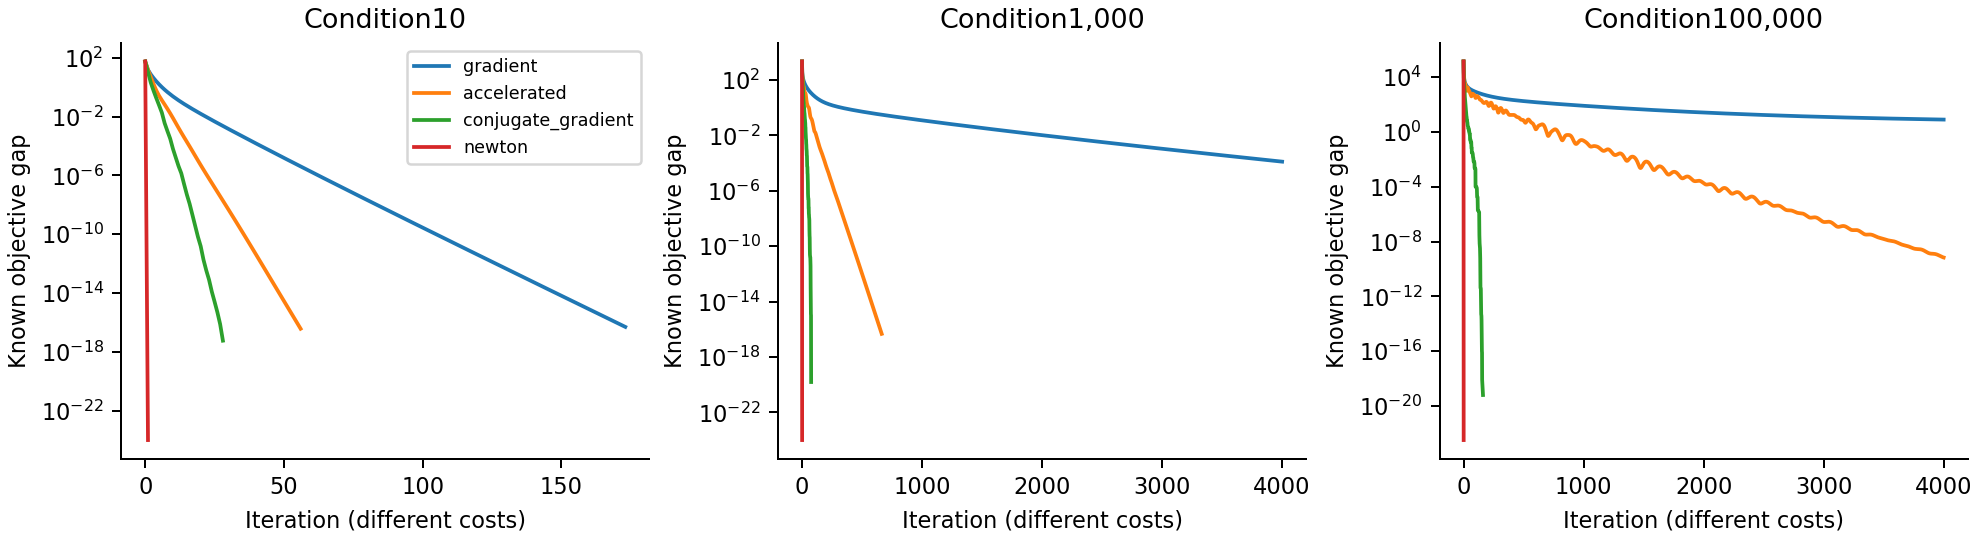

In [4]:
figure("quadratic_conditioning")

Full training / search commands and cache provenance are in [reproduction](../docs/reproduction.md). This notebook inspects actually completed evidence and small analytical checks; opening it does not launch the full fitting campaign.